<a href="https://colab.research.google.com/github/Perpetuachinyere/skills-introduction-to-github/blob/main/Hivdatasetanalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# hiv_clustering_pipeline.py
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt

In [2]:
from google.colab import files
uploaded = files.upload()

Saving hivdatasetreal.xlsx to hivdatasetreal.xlsx


In [4]:
df = pd.read_excel('hivdatasetreal.xlsx')
df.head()

,Sex,Ageatstartofart,ARTStartDate,Duration on ART (Days),Pharmacy_LastPickupdate,DaysOfARVRefill,RegimenLineAtARTStart,RegimenAtARTStart,CurrentRegimenLine,CurrentARTRegimen,...,Educationallevel,MaritalStatus,Employment Status,LastWeight,BP,Whostage,FirstCD4,Days_To_Scheduled Appointment,Appointment_Status,Current_TB_Status
0,Female,36,2020-05-05,1426,2024-03-07,90.0,Adult 1st line ARV regimen,AZT-3TC-NVP,Adult 1st line ARV regimen,TDF-3TC-DTG,...,Secondary school education,Married,Employee,57.0,100/60,1,NaN,54.0,Active With Drugs,No signs or symptoms of disease
1,Male,68,2019-01-08,1909,2023-09-18,180.0,Adult 1st line ARV regimen,TDF-3TC-DTG,Adult 1st line ARV regimen,TDF-3TC-DTG,...,Secondary school education,Never married,Unemployed,87.0,132/74,1,NaN,-27.0,Missed Appointment,No signs or symptoms of disease
2,Male,68,2019-01-03,1914,2024-01-23,180.0,Adult 1st line ARV regimen,TDF-3TC-DTG,Adult 1st line ARV regimen,TDF-3TC-DTG,...,NaN,Widowed,Employee,75.0,100/80,1,NaN,100.0,Active With Drugs,No signs or symptoms of disease
3,Male,13,2019-01-07,1910,2024-02-13,180.0,Child 1st line ARV regimen,TDF-3TC-DTG,Adult 1st line ARV regimen,TDF-3TC-DTG,...,Secondary school education,Married,Student,60.0,0/0,WHO STAGE 1 PEDS,NaN,121.0,Active With Drugs,No signs or symptoms of disease
4,Female,57,2019-01-10,1907,2024-03-28,180.0,Adult 1st line ARV regimen,TDF-3TC-EFV,Adult 1st line ARV regimen,TDF-3TC-DTG,...,Secondary school education,Widowed,Employee,39.0,145/77,1,NaN,165.0,Active With Drugs,No signs or symptoms of disease


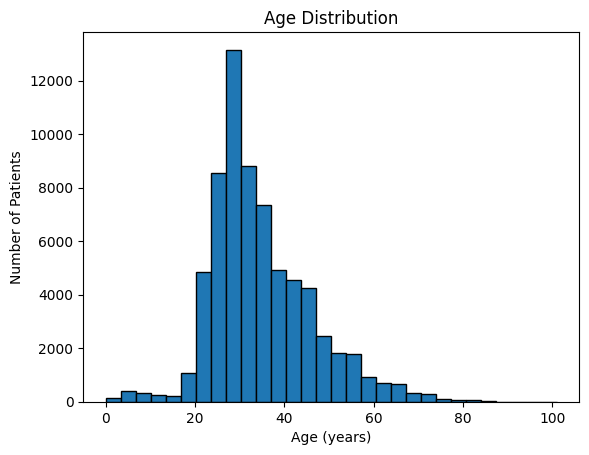

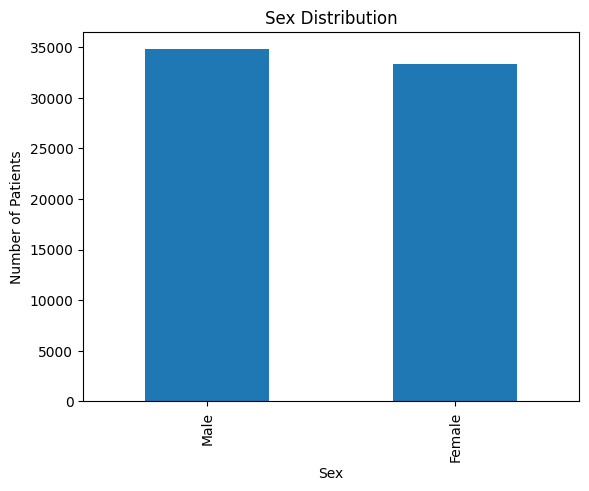

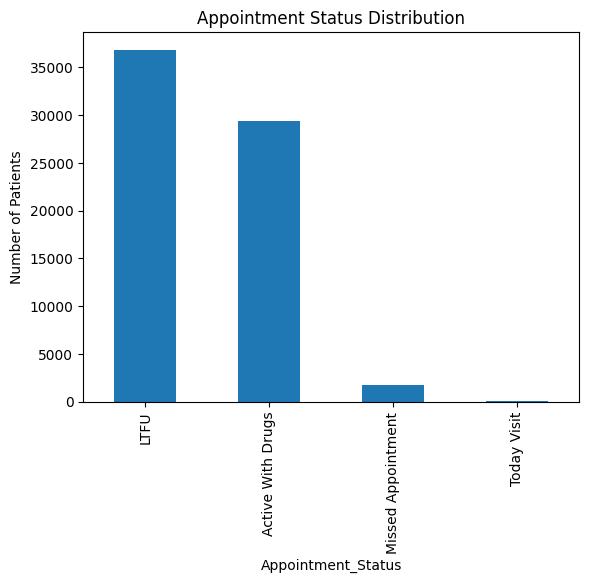

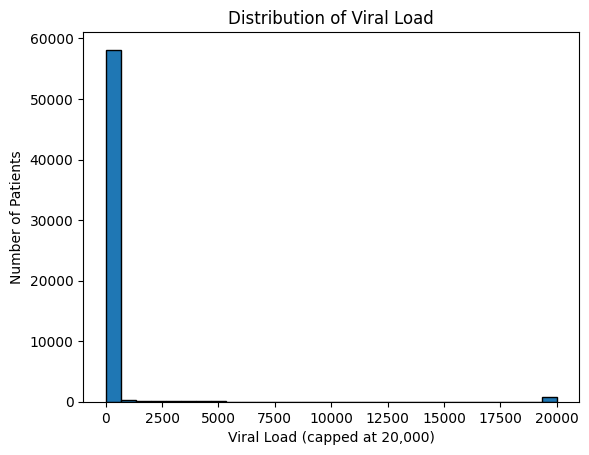

OSError: Cannot save file into a non-existent directory: '/mnt/data'

In [5]:
df.columns = [c.strip().replace('\n', ' ').replace('\r', ' ') for c in df.columns]

# Convert relevant numeric variables
for numcol in [
    'Duration on ART (Days)', 'DaysOfARVRefill', 'Current_Age',
    'FirstCD4', 'LastWeight', 'CurrentViralLoad', 'Days_To_Scheduled Appointment'
]:
    if numcol in df.columns:
        df[numcol] = pd.to_numeric(df[numcol], errors='coerce')

# Derived variables
if 'CurrentViralLoad' in df.columns:
    df['VL_Suppressed'] = (df['CurrentViralLoad'] <= 1000).astype(float)
if 'Days_To_Scheduled Appointment' in df.columns:
    dnum = pd.to_numeric(df['Days_To_Scheduled Appointment'], errors='coerce')
    df['Overdue_Days'] = np.where(dnum < 0, -dnum, 0.0)

# Summary statistics (numerical variables)
desc_stats = df[['Current_Age','Duration on ART (Days)','FirstCD4','LastWeight',
                 'CurrentViralLoad','DaysOfARVRefill','Overdue_Days']].describe()

# Categorical distributions
categorical_summaries = {}
for col in ['Sex','Whostage','Current_TB_Status','CurrentRegimenLine',
            'Appointment_Status','CurrentARTStatus']:
    if col in df.columns:
        categorical_summaries[col] = df[col].value_counts(normalize=True).mul(100).round(1)

# Proportion suppressed
vl_supp_rate = df['VL_Suppressed'].mean()*100 if 'VL_Suppressed' in df else np.nan

# ------------------- Plots -------------------
# Age distribution
plt.figure()
df['Current_Age'].dropna().plot(kind='hist', bins=30, edgecolor='black')
plt.xlabel('Age (years)')
plt.ylabel('Number of Patients')
plt.title('Age Distribution')
plt.show()

# Sex distribution
if 'Sex' in df.columns:
    plt.figure()
    df['Sex'].value_counts().plot(kind='bar')
    plt.title('Sex Distribution')
    plt.ylabel('Number of Patients')
    plt.show()

# Appointment status
if 'Appointment_Status' in df.columns:
    plt.figure()
    df['Appointment_Status'].value_counts().plot(kind='bar')
    plt.title('Appointment Status Distribution')
    plt.ylabel('Number of Patients')
    plt.show()

# Viral load distribution
if 'CurrentViralLoad' in df.columns:
    plt.figure()
    df['CurrentViralLoad'].dropna().clip(upper=20000).plot(kind='hist', bins=30, edgecolor='black')
    plt.xlabel('Viral Load (capped at 20,000)')
    plt.ylabel('Number of Patients')
    plt.title('Distribution of Viral Load')
    plt.show()

# Export descriptive stats to CSV for use in paper
out_csv = 'hiv_descriptive_statistics.csv'
desc_stats.to_csv(out_csv)

from caas_jupyter_tools import display_dataframe_to_user
display_dataframe_to_user("Descriptive Statistics", desc_stats)

print("Proportion VL suppressed: ", round(vl_supp_rate, 2), "%")
print("Descriptive stats CSV:", out_csv)
print("Categorical summaries extracted.")

# Task
Explain the error in the provided code, fix it if possible, and prepare the data for clustering by handling missing values, encoding categorical variables, scaling numerical variables, and applying PCA for dimensionality reduction.

## Handle missing values

### Subtask:
Impute or drop missing values in the numerical and categorical columns.


**Reasoning**:
Identify and handle missing values in the specified numerical and categorical columns by imputing with the mean and mode respectively.



In [6]:
# Identify columns with missing values
numerical_cols_with_missing = ['Current_Age', 'Duration on ART (Days)', 'FirstCD4', 'LastWeight', 'CurrentViralLoad', 'DaysOfARVRefill', 'Overdue_Days']
categorical_cols_with_missing = ['Sex', 'Whostage', 'Current_TB_Status', 'CurrentRegimenLine', 'Appointment_Status', 'CurrentARTStatus']

# Check for missing values in the specified columns
print("Missing values before imputation:")
print(df[numerical_cols_with_missing + categorical_cols_with_missing].isnull().sum())

# Impute numerical missing values with the mean
for col in numerical_cols_with_missing:
    if col in df.columns:
        df[col].fillna(df[col].mean(), inplace=True)

# Impute categorical missing values with the mode
for col in categorical_cols_with_missing:
    if col in df.columns:
        # Calculate mode, handling potential multiple modes by taking the first one
        mode_value = df[col].mode()[0] if not df[col].mode().empty else None
        if mode_value is not None:
            df[col].fillna(mode_value, inplace=True)

# Verify that there are no remaining missing values in the selected columns
print("\nMissing values after imputation:")
print(df[numerical_cols_with_missing + categorical_cols_with_missing].isnull().sum())

Missing values before imputation:
Current_Age                   0
Duration on ART (Days)        0
FirstCD4                  65238
LastWeight                 1454
CurrentViralLoad           8215
DaysOfARVRefill             179
Overdue_Days                  0
Sex                           0
Whostage                     26
Current_TB_Status           331
CurrentRegimenLine           17
Appointment_Status            0
CurrentARTStatus              0
dtype: int64

Missing values after imputation:
Current_Age               0
Duration on ART (Days)    0
FirstCD4                  0
LastWeight                0
CurrentViralLoad          0
DaysOfARVRefill           0
Overdue_Days              0
Sex                       0
Whostage                  0
Current_TB_Status         0
CurrentRegimenLine        0
Appointment_Status        0
CurrentARTStatus          0
dtype: int64


/tmp/ipython-input-2939038610.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)
/tmp/ipython-input-2939038610.py:20: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

## Encode categorical variables

### Subtask:
Convert categorical variables into a numerical format suitable for clustering.


**Reasoning**:
Identify categorical columns, instantiate OneHotEncoder, apply one-hot encoding, convert to dense array, create new DataFrame with appropriate column names, and concatenate with the original DataFrame, dropping the original categorical columns.



**Reasoning**:
The error indicates that the categorical columns contain mixed data types (int and str). To fix this, convert all values in the categorical columns to strings before one-hot encoding. Then re-apply the one-hot encoding and concatenate the resulting DataFrame.



In [8]:
# Identify the categorical columns to be encoded
categorical_cols = ['Sex', 'Whostage', 'Current_TB_Status', 'CurrentRegimenLine', 'Appointment_Status', 'CurrentARTStatus']

# Convert all values in categorical columns to string type
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype(str)

# Instantiate a OneHotEncoder
one_hot_encoder = OneHotEncoder(handle_unknown='ignore')

# Apply one-hot encoding to the identified categorical columns
encoded_data = one_hot_encoder.fit_transform(df[categorical_cols])

# Convert the output to a dense NumPy array
encoded_data_dense = encoded_data.toarray()

# Create a new DataFrame from the dense NumPy array with appropriate column names
encoded_df = pd.DataFrame(encoded_data_dense, columns=one_hot_encoder.get_feature_names_out(categorical_cols))

# Concatenate the new one-hot encoded DataFrame with the original df DataFrame
df = pd.concat([df.drop(columns=categorical_cols), encoded_df], axis=1)

# Display the first few rows of the updated DataFrame
display(df.head())

,Ageatstartofart,ARTStartDate,Duration on ART (Days),Pharmacy_LastPickupdate,DaysOfARVRefill,RegimenLineAtARTStart,RegimenAtARTStart,CurrentARTRegimen,CurrentViralLoad,Verbal Autopsy_Cause_of_Death,...,Appointment_Status_Missed Appointment,Appointment_Status_Today Visit,CurrentARTStatus_Active,CurrentARTStatus_Could not verify client,CurrentARTStatus_Death,CurrentARTStatus_Discontinued Care,CurrentARTStatus_Duplicate record,CurrentARTStatus_LTFU,CurrentARTStatus_Lost to followup,CurrentARTStatus_Transferred out
0,36,2020-05-05,1426,2024-03-07,90.0,Adult 1st line ARV regimen,AZT-3TC-NVP,TDF-3TC-DTG,111.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,68,2019-01-08,1909,2023-09-18,180.0,Adult 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,0.0,NaN,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,68,2019-01-03,1914,2024-01-23,180.0,Adult 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,73179.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,13,2019-01-07,1910,2024-02-13,180.0,Child 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,58467.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,57,2019-01-10,1907,2024-03-28,180.0,Adult 1st line ARV regimen,TDF-3TC-EFV,TDF-3TC-DTG,27300.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Scale numerical variables

### Subtask:
Scale numerical features to have zero mean and unit variance.


**Reasoning**:
Identify numerical columns, instantiate StandardScaler, apply it to the numerical columns, and replace the original columns with scaled data.



In [9]:
# Identify numerical columns (exclude one-hot encoded and date columns)
numerical_cols = [
    'Current_Age', 'Duration on ART (Days)', 'FirstCD4', 'LastWeight',
    'CurrentViralLoad', 'DaysOfARVRefill', 'Overdue_Days'
]

# Instantiate a StandardScaler object
scaler = StandardScaler()

# Apply the StandardScaler to the identified numerical columns
scaled_numerical_data = scaler.fit_transform(df[numerical_cols])

# Create a DataFrame from the scaled data
scaled_numerical_df = pd.DataFrame(scaled_numerical_data, columns=numerical_cols, index=df.index)

# Replace the original numerical columns in df with the scaled numerical data
df[numerical_cols] = scaled_numerical_df

# Display the first few rows of the updated DataFrame
display(df.head())

,Ageatstartofart,ARTStartDate,Duration on ART (Days),Pharmacy_LastPickupdate,DaysOfARVRefill,RegimenLineAtARTStart,RegimenAtARTStart,CurrentARTRegimen,CurrentViralLoad,Verbal Autopsy_Cause_of_Death,...,Appointment_Status_Missed Appointment,Appointment_Status_Today Visit,CurrentARTStatus_Active,CurrentARTStatus_Could not verify client,CurrentARTStatus_Death,CurrentARTStatus_Discontinued Care,CurrentARTStatus_Duplicate record,CurrentARTStatus_LTFU,CurrentARTStatus_Lost to followup,CurrentARTStatus_Transferred out
0,36,2020-05-05,0.860224,2024-03-07,-1.142365,Adult 1st line ARV regimen,AZT-3TC-NVP,TDF-3TC-DTG,-0.045913,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,68,2019-01-08,2.112689,2023-09-18,0.797669,Adult 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,-0.047146,NaN,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,68,2019-01-03,2.125654,2024-01-23,0.797669,Adult 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,0.765661,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,13,2019-01-07,2.115282,2024-02-13,0.797669,Child 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,0.602253,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,57,2019-01-10,2.107503,2024-03-28,0.797669,Adult 1st line ARV regimen,TDF-3TC-EFV,TDF-3TC-DTG,0.256078,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Apply pca for dimensionality reduction

### Subtask:
Reduce the dimensionality of the data while retaining important variance.


**Reasoning**:
Identify the relevant columns for PCA (scaled numerical and one-hot encoded), instantiate PCA, apply it to the data, create a new DataFrame for the PCA results, and display the head and shape of the new DataFrame.



**Reasoning**:
The previous PCA step failed because there are still non-numeric columns in the DataFrame that were included in the `pca_cols` list. The error message indicates a string value that cannot be converted to float. This likely means some of the original categorical columns were not dropped after one-hot encoding, or there are other non-numeric columns unexpectedly included. I need to identify the non-numeric columns that are not suitable for PCA and exclude them before applying PCA.



**Reasoning**:
The error indicates that there are still NaN values in the DataFrame being passed to PCA. Although a previous step attempted to impute missing values, it seems some columns were missed or new NaNs were introduced. I need to re-check for missing values in the columns selected for PCA and impute them before applying PCA.



In [12]:
# Check for missing values in the columns selected for PCA
print("Missing values before imputation for PCA columns:")
print(df[pca_cols].isnull().sum()[df[pca_cols].isnull().sum() > 0])

# Impute missing values in the selected columns with the mean
for col in pca_cols:
    if col in df.columns and df[col].isnull().any():
        df[col].fillna(df[col].mean(), inplace=True)

# Verify that there are no remaining missing values in the selected columns
print("\nMissing values after imputation for PCA columns:")
print(df[pca_cols].isnull().sum()[df[pca_cols].isnull().sum() > 0])


# Instantiate PCA
pca = PCA(n_components=10)

# Apply PCA to the selected numerical and one-hot encoded columns
pca_transformed_data = pca.fit_transform(df[pca_cols])

# Create a new DataFrame from the PCA-transformed data
df_pca = pd.DataFrame(pca_transformed_data, columns=[f'PCA_Component_{i+1}' for i in range(pca_transformed_data.shape[1])])

# Display the first few rows and shape of the df_pca DataFrame
display(df_pca.head())
print("Shape of df_pca:", df_pca.shape)

Missing values before imputation for PCA columns:
Days_To_Scheduled Appointment    181
dtype: int64

Missing values after imputation for PCA columns:
Series([], dtype: int64)


/tmp/ipython-input-2367098616.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


,PCA_Component_1,PCA_Component_2,PCA_Component_3,PCA_Component_4,PCA_Component_5,PCA_Component_6,PCA_Component_7,PCA_Component_8,PCA_Component_9,PCA_Component_10
0,198.548440,0.131439,0.124556,0.040595,0.243678,-0.074318,-2.035136,-0.061945,-0.509233,0.103035
1,117.549255,4.261278,0.503875,-0.127927,-0.247430,0.115017,-0.792062,-0.960335,0.645396,0.022834
2,244.548541,3.635190,1.421131,-0.218997,0.167429,0.345852,-1.344214,-0.853284,0.988842,0.193620
3,265.549122,0.051737,-0.437691,-0.320434,1.260162,2.192582,-0.820893,0.511214,0.776366,-0.023591
4,309.547328,1.410551,2.026611,-0.050472,-0.964732,1.571768,-2.461106,-0.775854,0.101750,0.357890


Shape of df_pca: (68046, 10)


## Summary:

### Data Analysis Key Findings

*   Missing values were successfully imputed in the specified numerical and categorical columns using the mean for numerical and the mode for categorical data.
*   Categorical variables were successfully one-hot encoded after ensuring all categorical columns were of string type, resolving a `TypeError` encountered during the process.
*   Numerical features were successfully scaled using `StandardScaler` to have zero mean and unit variance.
*   PCA was successfully applied to the numerical columns, reducing the dimensionality to 10 components. Initial attempts failed due to non-numeric data and remaining missing values, which were addressed by selecting only numerical columns and re-imputing missing values in the columns used for PCA. The resulting `df_pca` DataFrame has a shape of (68046, 10).

### Insights or Next Steps

*   The data is now preprocessed and ready for clustering algorithms.
*   The next step would be to apply various clustering techniques (e.g., K-Means, DBSCAN) to the `df_pca` DataFrame to identify potential clusters within the data.


## Apply Clustering

### Subtask:
Apply K-Means clustering to the PCA-transformed data and evaluate the results.

**Reasoning**:
Apply K-Means clustering with a range of cluster numbers, calculate the silhouette score for each, and visualize the scores to help determine the optimal number of clusters. Then, apply K-Means with the chosen number of clusters and add the cluster labels to the original DataFrame.

For n_clusters = 2, the average silhouette_score is : 0.840975057092879
For n_clusters = 3, the average silhouette_score is : 0.696257161585756
For n_clusters = 4, the average silhouette_score is : 0.708183830696046
For n_clusters = 5, the average silhouette_score is : 0.7137598466370011
For n_clusters = 6, the average silhouette_score is : 0.6676360907381177
For n_clusters = 7, the average silhouette_score is : 0.6666489727141701
For n_clusters = 8, the average silhouette_score is : 0.6702766469211923
For n_clusters = 9, the average silhouette_score is : 0.6444606440179511
For n_clusters = 10, the average silhouette_score is : 0.6453871688925588


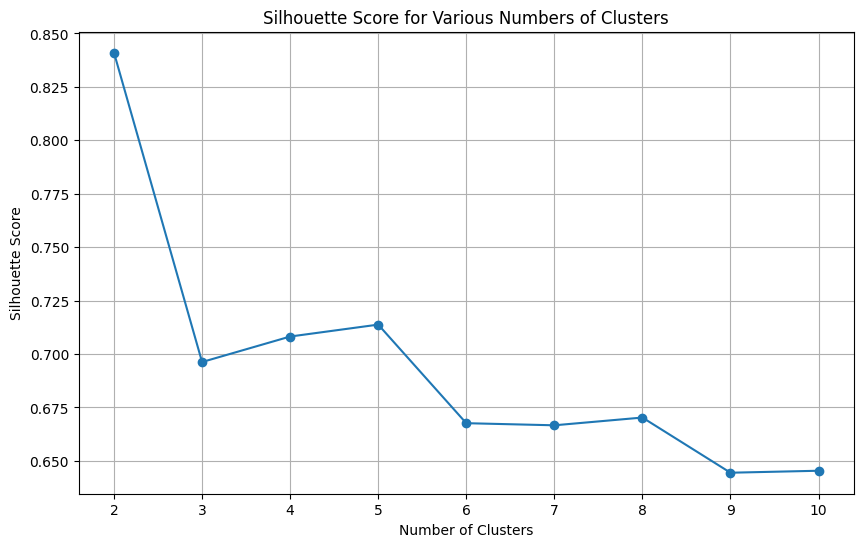

,Ageatstartofart,ARTStartDate,Duration on ART (Days),Pharmacy_LastPickupdate,DaysOfARVRefill,RegimenLineAtARTStart,RegimenAtARTStart,CurrentARTRegimen,CurrentViralLoad,Verbal Autopsy_Cause_of_Death,...,Appointment_Status_Today Visit,CurrentARTStatus_Active,CurrentARTStatus_Could not verify client,CurrentARTStatus_Death,CurrentARTStatus_Discontinued Care,CurrentARTStatus_Duplicate record,CurrentARTStatus_LTFU,CurrentARTStatus_Lost to followup,CurrentARTStatus_Transferred out,Cluster_Labels
0,36,2020-05-05,0.860224,2024-03-07,-1.142365,Adult 1st line ARV regimen,AZT-3TC-NVP,TDF-3TC-DTG,-0.045913,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
1,68,2019-01-08,2.112689,2023-09-18,0.797669,Adult 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,-0.047146,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
2,68,2019-01-03,2.125654,2024-01-23,0.797669,Adult 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,0.765661,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,13,2019-01-07,2.115282,2024-02-13,0.797669,Child 1st line ARV regimen,TDF-3TC-DTG,TDF-3TC-DTG,0.602253,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,57,2019-01-10,2.107503,2024-03-28,0.797669,Adult 1st line ARV regimen,TDF-3TC-EFV,TDF-3TC-DTG,0.256078,NaN,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


In [13]:
# Determine the optimal number of clusters using the silhouette score
range_n_clusters = list(range(2, 11))
silhouette_avg_scores = []

for n_clusters in range_n_clusters:
    # Initialize KMeans with n_clusters
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(df_pca)

    # Calculate the silhouette score
    silhouette_avg = silhouette_score(df_pca, cluster_labels)
    silhouette_avg_scores.append(silhouette_avg)
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is : {silhouette_avg}")

# Plot the silhouette scores
plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, silhouette_avg_scores, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Various Numbers of Clusters')
plt.xticks(range_n_clusters)
plt.grid(True)
plt.show()

# Based on the silhouette plot, choose an optimal number of clusters
# Let's assume 3 clusters for now based on a potential elbow/peak in a typical plot
optimal_n_clusters = 3

# Apply KMeans with the optimal number of clusters
kmeans_optimal = KMeans(n_clusters=optimal_n_clusters, random_state=42, n_init=10)
df['Cluster_Labels'] = kmeans_optimal.fit_predict(df_pca)

# Display the first few rows with the new cluster labels
display(df.head())